# Titanic Survival Prediction using Logistic Regression (from scratch)

Research AI Task 7

**Goal:** predict whether a passenger survived the Titanic, using a
**Logistic Regression model built from scratch** (no `scikit-learn`),
written as a simple Python class.

### What this notebook does
1. Load and explore the data (EDA)
2. Clean the data and prepare features
3. Split into train/test sets and scale the features
4. Build a simple `LogisticRegression` class (sigmoid + gradient descent,
   using only NumPy)
5. Train it and look at how the cost decreases
6. Evaluate it with accuracy, precision, recall, F1-score and a confusion
   matrix
7. Visualize the results

Every section has a short note on *why* that step is there, not just
*what* the code does.

## 1. Import libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)


## 2. Load the dataset

In [2]:

df = pd.read_csv("titanic.csv")
df.head()


## 3. Basic inspection

In [3]:

print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())


Shape: (891, 12)

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [4]:

print("Survived counts (0 = died, 1 = survived):")
print(df["Survived"].value_counts())
print("\nSurvival rate overall:", round(df["Survived"].mean(), 3))


Survived counts (0 = died, 1 = survived):
Survived
0    549
1    342
Name: count, dtype: int64

Survival rate overall: 0.384


## 4. Exploratory Data Analysis (EDA)

Before building the model, let's check which columns actually seem to be
linked to survival — this is what justifies which features we keep in
Section 5.

Women and 1st class passengers clearly survived at a much higher rate
-> Sex and Pclass look like strong predictors, worth keeping as features.


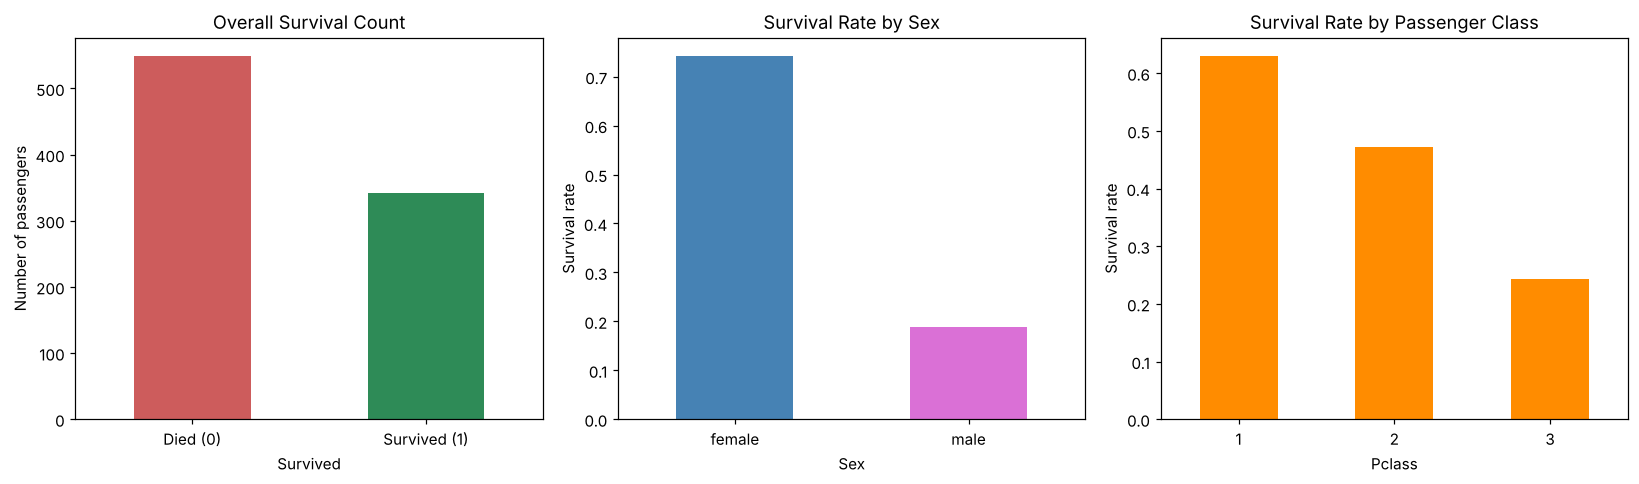

In [5]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

df["Survived"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["indianred", "seagreen"]
)
axes[0].set_xticklabels(["Died (0)", "Survived (1)"], rotation=0)
axes[0].set_title("Overall Survival Count")
axes[0].set_ylabel("Number of passengers")

df.groupby("Sex")["Survived"].mean().plot(
    kind="bar", ax=axes[1], color=["steelblue", "orchid"]
)
axes[1].set_title("Survival Rate by Sex")
axes[1].set_ylabel("Survival rate")
axes[1].tick_params(axis="x", rotation=0)

df.groupby("Pclass")["Survived"].mean().plot(
    kind="bar", ax=axes[2], color="darkorange"
)
axes[2].set_title("Survival Rate by Passenger Class")
axes[2].set_ylabel("Survival rate")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Women and 1st class passengers clearly survived at a much higher rate")
print("-> Sex and Pclass look like strong predictors, worth keeping as features.")


Younger passengers and passengers who paid a higher fare (likely richer,
higher class) survived somewhat more often.


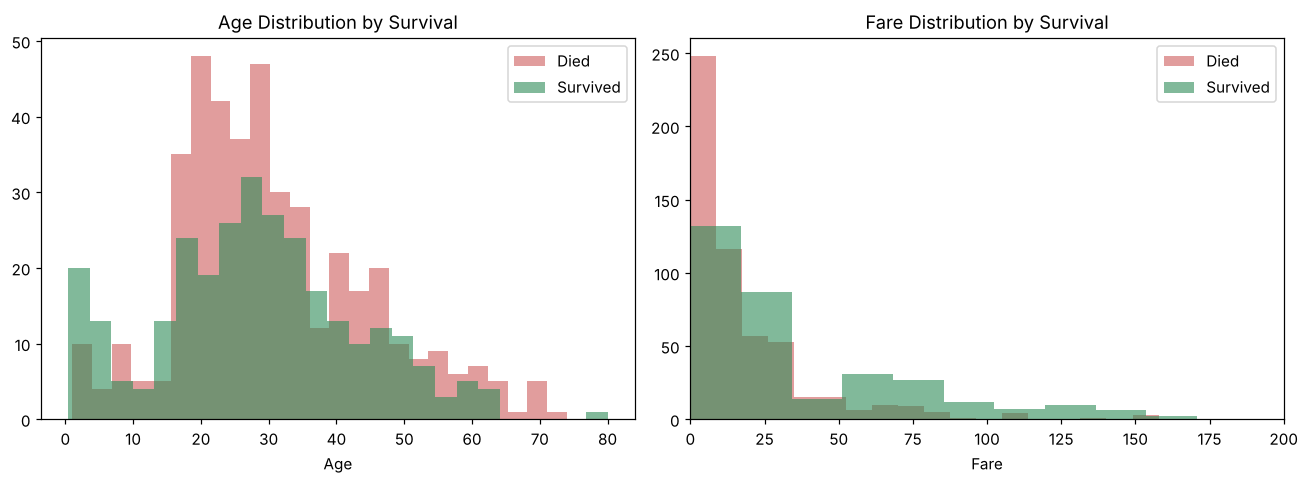

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(df[df["Survived"] == 0]["Age"].dropna(), bins=25, alpha=0.6, label="Died", color="indianred")
axes[0].hist(df[df["Survived"] == 1]["Age"].dropna(), bins=25, alpha=0.6, label="Survived", color="seagreen")
axes[0].set_title("Age Distribution by Survival")
axes[0].set_xlabel("Age")
axes[0].legend()

axes[1].hist(df[df["Survived"] == 0]["Fare"], bins=30, alpha=0.6, label="Died", color="indianred")
axes[1].hist(df[df["Survived"] == 1]["Fare"], bins=30, alpha=0.6, label="Survived", color="seagreen")
axes[1].set_title("Fare Distribution by Survival")
axes[1].set_xlabel("Fare")
axes[1].set_xlim(0, 200)
axes[1].legend()

plt.tight_layout()
plt.show()

print("Younger passengers and passengers who paid a higher fare (likely richer,")
print("higher class) survived somewhat more often.")


## 5. Data cleaning & feature selection

- `PassengerId`, `Name`, `Ticket`, `Cabin` are dropped: `PassengerId` is
  just a row number, `Name`/`Ticket` are mostly unique text with no
  direct numeric meaning, and `Cabin` is missing for ~77% of passengers
  (687 out of 891) — too sparse to use reliably.
- `Age` has 177 missing values. We fill them with the **median age**
  (median is less affected by outliers than the mean).
- `Embarked` has 2 missing values. We fill them with the **most common
  port** (the mode).
- `Sex` is turned into a simple 0/1 column (`male` = 0, `female` = 1) —
  it only has two categories, so one-hot encoding isn't even necessary.
- `Embarked` has three categories (C, Q, S), so it's one-hot encoded with
  `drop_first=True` to avoid the dummy-variable trap.

**Important:** the median age and the mode of `Embarked` are computed
**after** the train/test split (Section 6) using only the training data,
so no information from the test set leaks into preprocessing.

In [7]:

data = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

data["Sex"] = data["Sex"].map({"male": 0, "female": 1})

data = pd.get_dummies(data, columns=["Embarked"], drop_first=True, dtype=float)

print("Columns used as features:")
print([c for c in data.columns if c != "Survived"])
data.head()


Columns used as features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']


## 6. Train-test split

In [8]:

y = data["Survived"].to_numpy()
X_df = data.drop(columns=["Survived"])

X = X_df.to_numpy()

rng = np.random.default_rng(42)
indices = rng.permutation(len(X))
split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))


Training samples: 712
Testing samples : 179


### 6.1 Fill missing values (using training-set statistics only)

In [9]:

age_col = X_df.columns.get_loc("Age")

median_age_train = np.nanmedian(X_train[:, age_col])
print("Median age (from training set):", median_age_train)

X_train[np.isnan(X_train[:, age_col]), age_col] = median_age_train
X_test[np.isnan(X_test[:, age_col]), age_col] = median_age_train

print("Missing values left in X_train:", np.isnan(X_train).sum())
print("Missing values left in X_test :", np.isnan(X_test).sum())


Median age (from training set): 28.0
Missing values left in X_train: 0
Missing values left in X_test : 0


## 7. Feature scaling

Gradient Descent works much better when every feature is on a similar
scale — `Fare` ranges up to the hundreds while `Sex` is just 0 or 1.
We standardize: `(x - mean) / std`, using the mean/std **from the
training set only**, then apply the same numbers to the test set.

In [10]:

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1  # just in case a column has zero variance

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Features scaled. Example — first training row before vs conceptually after scaling.")


Features scaled. Example — first training row before vs conceptually after scaling.


## 8. Logistic Regression from scratch (class structure)

### The math

Logistic Regression predicts the **probability** of survival using the
sigmoid function:

$$\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = Xw + b$$

$\sigma(z)$ squashes any real number into the range (0, 1), so it can be
read as a probability. We classify a passenger as "survived" if
$\hat{y} \geq 0.5$.

We train by minimizing the **Binary Cross-Entropy (log) loss**:

$$J(w, b) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i\log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)\Big]$$

and we minimize it with **Batch Gradient Descent**, using these
gradients (they come out almost identical in form to linear
regression's, because of how neatly the sigmoid and log-loss combine):

$$\frac{\partial J}{\partial w} = \frac{1}{m}X^{T}(\hat{y} - y), \qquad
\frac{\partial J}{\partial b} = \frac{1}{m}\sum(\hat{y} - y)$$

Wrapping this in a class keeps the model self-contained: create it once
with `LogisticRegression()`, then call `.fit()` and `.predict()` on it,
just like a real library would.

In [11]:

class LogisticRegression:

    def __init__(self, learning_rate=0.1, iterations=2000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.cost_history = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.cost_history = []

        for i in range(self.iterations):
            # predicted probabilities
            z = np.dot(X, self.weights) + self.bias
            y_pred = self.sigmoid(z)

            # gradients (how much to adjust weights and bias by)
            dw = np.dot(X.T, (y_pred - y)) / n_samples
            db = np.sum(y_pred - y) / n_samples

            # update weights and bias
            self.weights = self.weights - self.learning_rate * dw
            self.bias = self.bias - self.learning_rate * db

            # track cost so we can plot it later
            cost = -np.mean(y * np.log(y_pred + 1e-9) + (1 - y) * np.log(1 - y_pred + 1e-9))
            self.cost_history.append(cost)

    def predict_proba(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.sigmoid(z)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return np.array([1 if p >= 0.5 else 0 for p in probabilities])


print("LogisticRegression class defined.")


LogisticRegression class defined.


### 8.1 Train the model

In [12]:

model = LogisticRegression(learning_rate=0.1, iterations=2000)
model.fit(X_train, y_train)

print("Training finished.")
print("Final training cost:", round(model.cost_history[-1], 4))
print("Learned weights:", np.round(model.weights, 3))
print("Learned bias:", round(model.bias, 3))


Training finished.
Final training cost: 0.4297
Learned weights: [-0.999  1.344 -0.641 -0.465 -0.055  0.079  0.011 -0.14 ]
Learned bias: -0.663


Cost drops quickly and then flattens out -> the model has converged.


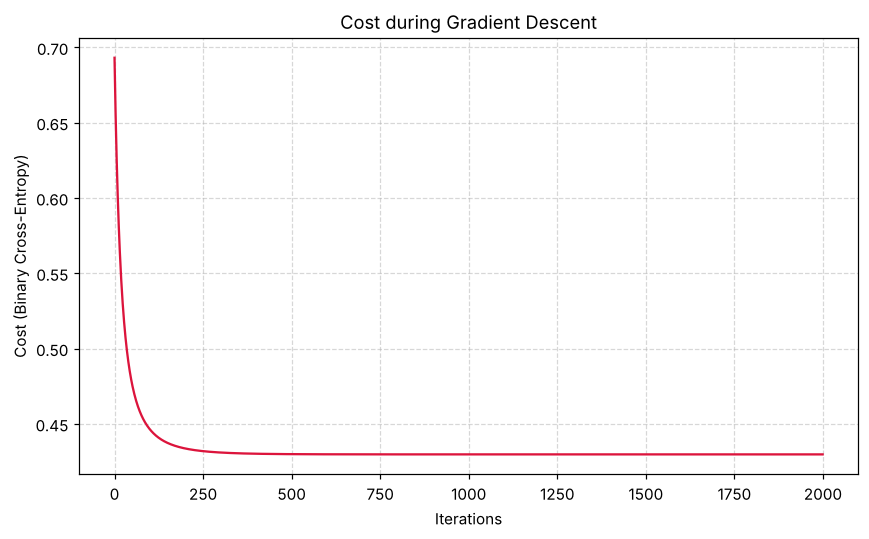

In [13]:

plt.figure(figsize=(8, 5))
plt.plot(model.cost_history, color="crimson")
plt.xlabel("Iterations")
plt.ylabel("Cost (Binary Cross-Entropy)")
plt.title("Cost during Gradient Descent")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print("Cost drops quickly and then flattens out -> the model has converged.")


## 9. Predictions

In [14]:

y_pred_proba = model.predict_proba(X_test)
y_pred = model.predict(X_test)

print("First 10 actual labels   :", y_test[:10])
print("First 10 predicted labels:", y_pred[:10])
print("First 10 predicted probabilities:", np.round(y_pred_proba[:10], 2))


First 10 actual labels   : [0 0 1 0 0 1 0 0 0 1]
First 10 predicted labels: [1 0 1 0 1 1 0 0 0 0]
First 10 predicted probabilities: [0.55 0.09 0.93 0.13 0.64 0.71 0.05 0.09 0.09 0.29]


## 10. Model evaluation

Accuracy alone can be misleading for classification (e.g. if one class
is much bigger than the other), so we compute a few metrics, all by
hand from the confusion matrix counts:

- **TP** (True Positive): predicted survived, actually survived
- **TN** (True Negative): predicted died, actually died
- **FP** (False Positive): predicted survived, actually died
- **FN** (False Negative): predicted died, actually survived

$$\text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN}, \quad
\text{Precision} = \frac{TP}{TP+FP}, \quad
\text{Recall} = \frac{TP}{TP+FN}, \quad
F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

In [15]:

TP = np.sum((y_pred == 1) & (y_test == 1))
TN = np.sum((y_pred == 0) & (y_test == 0))
FP = np.sum((y_pred == 1) & (y_test == 0))
FN = np.sum((y_pred == 0) & (y_test == 1))

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print(f"{'Metric':<12}{'Value':>10}")
print("-" * 22)
print(f"{'Accuracy':<12}{accuracy:>10.3f}")
print(f"{'Precision':<12}{precision:>10.3f}")
print(f"{'Recall':<12}{recall:>10.3f}")
print(f"{'F1-score':<12}{f1:>10.3f}")

print(f"\nConfusion matrix counts -> TP={TP}  TN={TN}  FP={FP}  FN={FN}")


Metric           Value
----------------------
Accuracy         0.732
Precision        0.633
Recall           0.725
F1-score         0.676

Confusion matrix counts -> TP=50  TN=81  FP=29  FN=19


### 10.1 Confusion matrix (visualized)

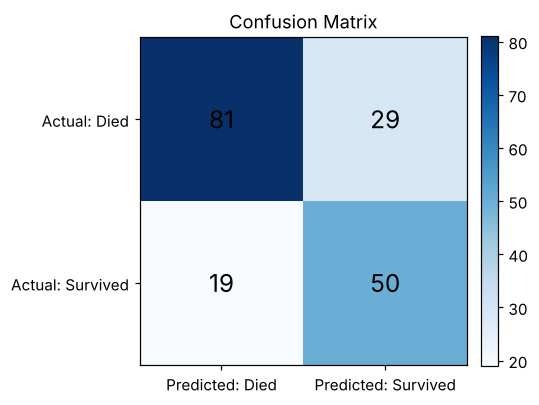

In [16]:

conf_matrix = np.array([[TN, FP],
                         [FN, TP]])

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(conf_matrix, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted: Died", "Predicted: Survived"])
ax.set_yticklabels(["Actual: Died", "Actual: Survived"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, conf_matrix[i, j], ha="center", va="center",
                 fontsize=16, color="black")

plt.title("Confusion Matrix")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## 11. Actual vs predicted probability

This plot shows, for every test passenger, the probability the model
assigned to "survived" — colored by what actually happened. Ideally,
died-passengers (red) cluster near 0 and survived-passengers (green)
cluster near 1, with the dashed line at 0.5 being the decision
threshold.

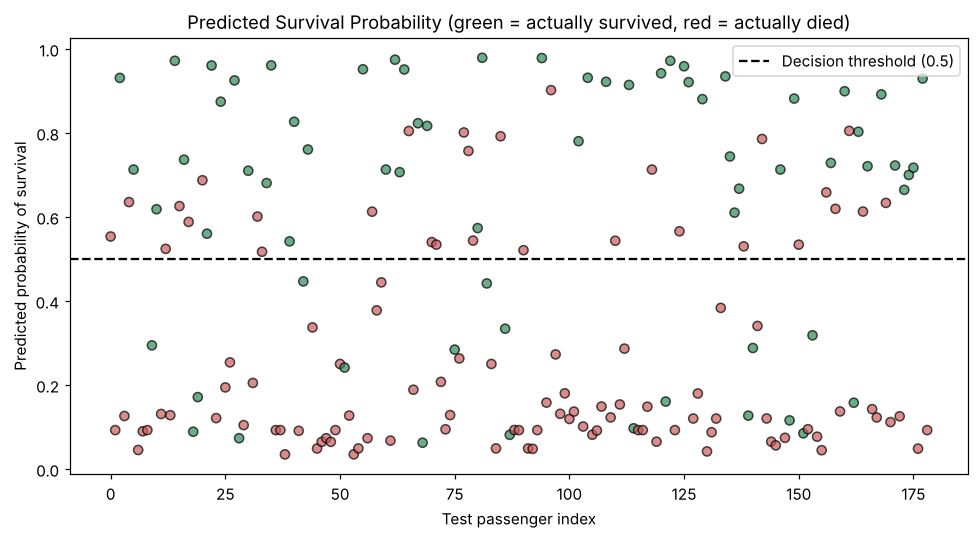

In [17]:

plt.figure(figsize=(9, 5))
plt.scatter(range(len(y_test)), y_pred_proba,
            c=["seagreen" if label == 1 else "indianred" for label in y_test],
            alpha=0.7, edgecolor="k")
plt.axhline(0.5, color="black", linestyle="--", label="Decision threshold (0.5)")
plt.xlabel("Test passenger index")
plt.ylabel("Predicted probability of survival")
plt.title("Predicted Survival Probability (green = actually survived, red = actually died)")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Which features matter most?

Because every feature was standardized before training, the learned
weights are directly comparable to each other. A positive weight pushes
the predicted probability of survival up; a negative weight pushes it
down.

Green bars increase survival probability, red bars decrease it.


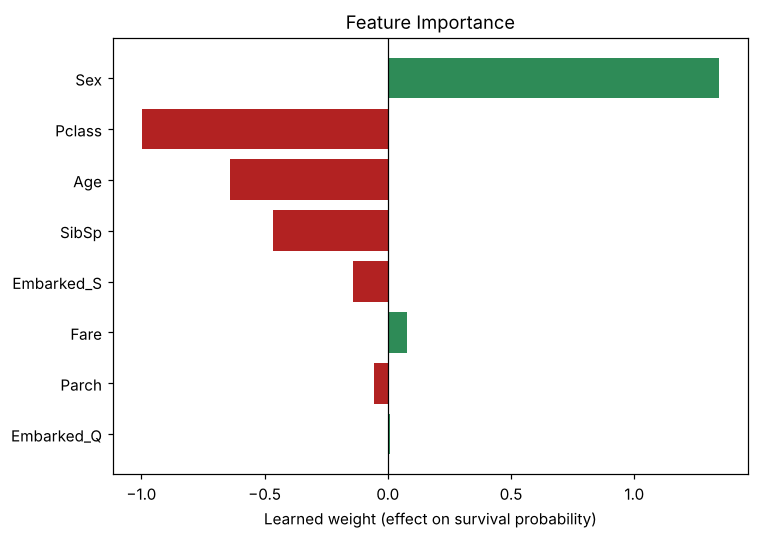

In [18]:

weights_df = pd.DataFrame({"feature": X_df.columns, "weight": model.weights})
weights_df = weights_df.reindex(weights_df["weight"].abs().sort_values(ascending=False).index)

plt.figure(figsize=(7, 5))
colors = ["seagreen" if w > 0 else "firebrick" for w in weights_df["weight"]]
plt.barh(weights_df["feature"], weights_df["weight"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel("Learned weight (effect on survival probability)")
plt.title("Feature Importance")
plt.tight_layout()
plt.show()

print("Green bars increase survival probability, red bars decrease it.")


## 13. Result

- Built a **Logistic Regression classifier from scratch**, as a Python
  class (`LogisticRegression`), trained with **Batch Gradient
  Descent** on the Binary Cross-Entropy loss — no `scikit-learn` used
  anywhere.
- After cleaning the data (dropping unusable columns, filling missing
  `Age`/`Embarked`, encoding `Sex`/`Embarked`, standardizing numeric
  features) and training for 2000 iterations, the cost curve flattens
  out, confirming the model converged.
- See Section 10 for the exact test-set Accuracy, Precision, Recall and
  F1-score, and the confusion matrix for the full breakdown of correct
  vs incorrect predictions.
- `Sex` and `Pclass` come out as the strongest predictors (Section 12),
  which matches the EDA in Section 4 and the well-known "women and
  first-class passengers first" pattern from the actual Titanic
  evacuation.

### Possible future improvements
- Add an `L2` regularization term to the cost function to reduce
  overfitting.
- Engineer a `FamilySize = SibSp + Parch + 1` feature.
- Try different classification thresholds (instead of a fixed 0.5) and
  look at the precision/recall trade-off.
